# Lab 06: Parsing Static Web Pages

*INFO 4617/5617 · Week 6 · Chapter 6, [Parsing Static Web Pages](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-06-static-pages.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it.

By the end you'll have turned four shapes of web page into DataFrames: a box-office chart that ships a decoy table, a Wikipedia table whose numbers need cleaning, a film's infobox in three languages, and the Oscars' award cards across several ceremonies. Before any of that, you'll ask each of the chapter's sites whether it wants to be scraped at all.

**The case:** the chapter's own, the movies: The Numbers' box office for the last week of 2018, Wikipedia's [List of highest-grossing films](https://en.wikipedia.org/wiki/List_of_highest-grossing_films), *The Godfather*, and the [98th Academy Awards](https://www.oscars.org/oscars/ceremonies/2026). Once a step works, try it on a page you care about.

**Before class:** open this notebook in the `webdata` environment (week 1), have your email address ready for the User-Agent, and open the [2026 ceremony page](https://www.oscars.org/oscars/ceremonies/2026) in Chrome next to this week's handout, *Cards to rows*: we'll Inspect it in Step 7.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Every cell is filled in and was run against the live sites on 2026-10-21, following the textbook at commit d9306b7. The Numbers' 2018 chart, the Wikipedia list (pinned to revision 1381243185), and the Oscars ceremonies will match a rerun; the three *Godfather* infoboxes can change with any edit, and Rotten Tomatoes' in-theaters grid (Step 9) changes every week. The chapter's pages for Strategies 1 and 8, on Box Office Mojo and IMDb, are never requested: their `robots.txt` disallows every crawler it doesn't name (Step 1). Every cell ran live.

## Step 0 — Set up (4 minutes)

Import `requests`, `time`, `StringIO` (from `io`; Step 3 needs it), `BeautifulSoup`, `pandas`, and `matplotlib`. Then define the User-Agent our requests will send, once. `HEADERS` is the book's form, `WebDataScience/1.0 (your-email@colorado.edu)`, with your own address, which week 2 explained: a site's operator can see who is asking and write to you. Wikimedia's [User-Agent policy](https://foundation.wikimedia.org/wiki/Policy:Wikimedia_Foundation_User-Agent_Policy) also asks for the library and its version, so `WIKI_HEADERS` adds `python-requests/` and `requests.__version__`, for Wikipedia. Why not one for every site? Step 2 shows.

In [1]:
# Import requests, time, StringIO (from io), BeautifulSoup (from bs4), pandas as pd, matplotlib.pyplot as plt
# Define CLIENT as "WebDataScience/1.0 (your-email@colorado.edu)", with your email, and HEADERS = {"User-Agent": CLIENT}
# Define WIKI_HEADERS for Wikipedia: its "User-Agent" is CLIENT, a space, "python-requests/", and requests.__version__
import requests
import time
from io import StringIO
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

CLIENT = "WebDataScience/1.0 (your-email@colorado.edu)"
HEADERS = {"User-Agent": CLIENT}
WIKI_HEADERS = {"User-Agent": f"{CLIENT} python-requests/{requests.__version__}"}
print(HEADERS["User-Agent"])
print(WIKI_HEADERS["User-Agent"])

WebDataScience/1.0 (your-email@colorado.edu)
WebDataScience/1.0 (your-email@colorado.edu) python-requests/2.34.2


<details>
<summary>💬 Discuss</summary>

- In week 2 we put a contact address in our User-Agent. Who reads it, and what can they do with it?
- The chapter says oscars.org turns away a User-Agent that pretends to be Chrome but lets in one that names you. Week 5 showed how easy spoofing is: why would it get you less here, not more?

</details>

## Step 1 — Check before you scrape (6 minutes)

The chapter's eight strategies send requests to six sites. Before we send any of them one, ask each site's `robots.txt` whether a crawler may fetch the chapter's page, as week 2 did: fetch the file yourself with `HEADERS`, hand its lines to a [`RobotFileParser`](https://docs.python.org/3/library/urllib.robotparser.html) with `rp.parse()`, and ask `rp.can_fetch(CLIENT, page)`. Week 5's [`urlparse()`](https://docs.python.org/3/library/urllib.parse.html#urllib.parse.urlparse) gives each page's host. The chapter's pages, in the order of its strategies (1, 2, 3, 6, 7, 8):

```python
CHAPTER_PAGES = [
    "https://www.boxofficemojo.com/weekend/2018W52/",
    "https://www.the-numbers.com/box-office-chart/weekly/2018/12/28",
    "https://en.wikipedia.org/wiki/List_of_highest-grossing_films",
    "https://www.oscars.org/oscars/ceremonies/2026",
    "https://www.rottentomatoes.com/browse/movies_in_theaters/",
    "https://www.imdb.com/title/tt0068646/",
]
```

In [2]:
# Import RobotFileParser (urllib.robotparser) and urlparse (urllib.parse); copy CHAPTER_PAGES from above
# For each page: fetch https://<its host>/robots.txt with HEADERS, stop if the status isn't 200,
#   parse its lines, and print the host and can_fetch(CLIENT, page); sleep 1 second between sites
from urllib.robotparser import RobotFileParser
from urllib.parse import urlparse

CHAPTER_PAGES = [
    "https://www.boxofficemojo.com/weekend/2018W52/",
    "https://www.the-numbers.com/box-office-chart/weekly/2018/12/28",
    "https://en.wikipedia.org/wiki/List_of_highest-grossing_films",
    "https://www.oscars.org/oscars/ceremonies/2026",
    "https://www.rottentomatoes.com/browse/movies_in_theaters/",
    "https://www.imdb.com/title/tt0068646/",
]

for page in CHAPTER_PAGES:
    host = urlparse(page).netloc
    response = requests.get(f"https://{host}/robots.txt", headers=HEADERS, timeout=30)
    response.raise_for_status()
    rp = RobotFileParser()
    rp.parse(response.text.splitlines())
    print(f"{host:26} may fetch: {rp.can_fetch(CLIENT, page)}")
    time.sleep(1)

www.boxofficemojo.com      may fetch: False


www.the-numbers.com        may fetch: True


en.wikipedia.org           may fetch: True


www.oscars.org             may fetch: True


www.rottentomatoes.com     may fetch: True


www.imdb.com               may fetch: False


<details>
<summary>💬 Discuss</summary>

- Open boxofficemojo.com/robots.txt in your browser. Its first lines are comments about scraping, pointing to IMDb's Conditions of Use. In week 2's terms, which binds us: the `Disallow` line, the conditions, or neither?
- The chapter's code runs without an error against both sites. Is "it works" a reason to run it?
- `robots.txt` speaks to crawlers. Is one request that a person sends from a notebook crawling? Where would you draw the line?

</details>

## Step 2 — The table hiding among decoys (12 minutes)

Step 1 found that Box Office Mojo and IMDb (one company owns both) disallow every path to every crawler their files don't name, so we leave their pages alone: Strategy 1's lesson, one `read_html()` call for one clean table, comes back in Step 3 on Wikipedia, and Step 9 finds another page for Strategy 8.

Strategy 2. The Numbers' weekly chart for the week ending December 28, 2018 ships two `<table>`s: one for wide screens and one for phones. Ask for it once with `WIKI_HEADERS` and print only the status; then fetch it with `HEADERS`, parse it with [BeautifulSoup](https://www.crummy.com/software/BeautifulSoup/bs4/doc/), and list every table with its `class` and its number of rows before you choose one. Then walk the table cell by cell with [`find_all(["td", "th"])`](https://www.crummy.com/software/BeautifulSoup/bs4/doc/#find-all), as the chapter does: it keeps an empty cell as `""` instead of dropping it, so every value stays under its column, and the guard prints each row it skips so you can see what you threw away. See the chapter's "Strategy 2: The Table Hiding Among Decoys".

In [3]:
# Request the 2018-12-28 chart with WIKI_HEADERS and print the status; fetch it with HEADERS, parse ("html.parser")
# Print each table's index, class, and number of <tr> rows; take the one whose class says "desktop"
# header = the first row's cell texts; keep each other row's cell texts if it has as many cells as the header,
#   or print it as skipped. Make a DataFrame, weekly; print its shape and head()
url = "https://www.the-numbers.com/box-office-chart/weekly/2018/12/28"
print("With WIKI_HEADERS:", requests.get(url, headers=WIKI_HEADERS, timeout=30).status_code)
time.sleep(1)
response = requests.get(url, headers=HEADERS, timeout=30)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")

tables = soup.find_all("table")
for i, table in enumerate(tables):
    print(i, table.get("class"), len(table.find_all("tr")), "rows")

data_table = soup.find("table", class_="chart-desktop")
rows = data_table.find_all("tr")
header = [cell.get_text(strip=True) for cell in rows[0].find_all(["td", "th"])]
print(header)

all_rows = []
for row in rows[1:]:
    values = [cell.get_text(strip=True) for cell in row.find_all(["td", "th"])]
    if len(values) != len(header):
        print(f"Skipping row with {len(values)} cells: {values[:3]}")
        continue
    all_rows.append(values)

weekly = pd.DataFrame(all_rows, columns=header)
print(weekly.shape)
weekly.head()

With WIKI_HEADERS: 403


0 ['chart-desktop'] 84 rows
1 ['chart-mobile'] 84 rows
['Rank', 'Prev', 'Title', 'Gross', 'WeeklyChange', 'Theaters', 'TheaterAverage', 'Total\xa0Gross', 'Days in Release']
Skipping row with 1 cells: ['']
Skipping row with 5 cells: ['', '', 'Reporting movies: 81']
(81, 9)


,Rank,Prev,Title,Gross,WeeklyChange,Theaters,TheaterAverage,Total Gross,Days in Release
0,1,(1),Aquaman,"$92,087,265",-30%,"4,125","$22,324","$229,020,880",14
1,2,(2),Mary Poppins Returns,"$52,045,547",-16%,"4,090","$12,725","$122,956,305",16
2,3,(3),Bumblebee,"$38,075,120",-18%,"3,550","$10,725","$84,353,140",14
3,4,(4),Spider-Man: Into The Spider-Verse 3D,"$35,522,616",-5%,"3,813","$9,316","$120,851,346",21
4,5,(5),The Mule,"$23,120,925",-1%,"2,787","$8,296","$72,068,110",21


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** the chapter takes `tables[1]`, the `chart-mobile` table. Parse the same `response.text` twice more, once with `"html.parser"` and once with `"lxml"`, find `chart-mobile` in each, and count its rows and the cells in each of its first three rows.
**Share:** how many cells the first data row has under each parser, and how many rows the chapter's loop would have kept from it.

In [4]:
# Microsprint: for parser in "html.parser" and "lxml": parse response.text again, find the chart-mobile table,
#   and print the parser, its number of rows, and the number of cells in each of its first three rows
for parser in ["html.parser", "lxml"]:
    mobile = BeautifulSoup(response.text, parser).find("table", class_="chart-mobile")
    mobile_rows = mobile.find_all("tr")
    print(f"{parser:12} {len(mobile_rows)} rows; cells in the first three:",
          [len(row.find_all(["td", "th"])) for row in mobile_rows[:3]])

html.parser  84 rows; cells in the first three: [5, 405, 400]
lxml         84 rows; cells in the first three: [5, 5, 5]


<details>
<summary>💬 Discuss</summary>

- The Numbers refused `WIKI_HEADERS` with a 403 and accepted `HEADERS`; the only difference is `python-requests/` at the end. Week 5 said a 403 is often about the User-Agent: what is this server filtering on, and is that a reason to drop the library's name everywhere?
- Both tables have 84 rows, so the chapter's rule of thumb, "the main data table is usually the largest one", can't choose. What did, and where would week 5's Inspector have shown it to you?
- The phone table never closes its `<tr>` tags. Why do the two parsers disagree about it, and is either one wrong?

</details>

## Step 3 — One call for a whole table: `read_html()` (5 minutes)

Strategies 1 and 3. When the data sits in a real `<table>`, [`pd.read_html()`](https://pandas.pydata.org/docs/reference/api/pandas.read_html.html) does Step 2's work in one call and returns every table on the page as a list of DataFrames. The chapter points it straight at a URL with `storage_options=headers`. We fetch the page once with `requests` instead, so it carries `WIKI_HEADERS` and we can check the status, and hand `read_html` the text, wrapped in `StringIO`: pandas 3 reads a bare string as a file name. One request, parsed as often as we like.

The list changes every week while films are in theaters, so we ask for one revision of it: `https://en.wikipedia.org/wiki/List_of_highest-grossing_films?oldid=1381243185`. (The **Permanent link** in the article's Tools menu gives the same revision at `/w/index.php`, a path Wikipedia's `robots.txt` disallows; `/wiki/` with `?oldid=` is allowed.)

In [5]:
# Define WIKI_URL, the address above; fetch it with WIKI_HEADERS and stop if the status isn't 200
# Run pd.read_html on StringIO(response.text) with header=0, and print how many tables it found
# films = the first table; print the first ten unique values of "Worldwide gross", then show films.head()
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_highest-grossing_films?oldid=1381243185"
response = requests.get(WIKI_URL, headers=WIKI_HEADERS, timeout=30)
response.raise_for_status()

tables = pd.read_html(StringIO(response.text), header=0)
print(f"Number of tables found: {len(tables)}")

films = tables[0]
print(films["Worldwide gross"].unique()[:10])
films.head()

Number of tables found: 92
<StringArray>
[  '$2,941,331,540',   '$2,923,710,708',   '$2,516,315,789',
   '$2,334,484,620',  'T$2,257,906,828', 'NZ$2,217,758,382',
   '$2,068,223,624',   '$2,048,359,754', 'SM$1,922,598,800',
   '$1,870,309,291']
Length: 10, dtype: str


,Rank,Peak,Title,Worldwide gross,Year,Ref
0,1,1,Avengers: Endgame †,"$2,941,331,540",2019,[# 1][# 2]
1,2,1,Avatar,"$2,923,710,708",2009,[# 3][# 4]
2,3,3,Spider-Man: Brand New Day †,"$2,516,315,789",2026,[# 5]
3,4,3,Avatar: The Way of Water,"$2,334,484,620",2022,[# 6][# 7]
4,5,1,Titanic,"T$2,257,906,828",1997,[# 8][# 9]


<details>
<summary>💬 Discuss</summary>

- `read_html` found 92 tables on one page and we took the first on faith. Its `match=` argument (see its documentation) would choose for us: by what?
- Week 1's first request fetched a Wikipedia article as raw HTML. What did `read_html` do with the same kind of text that we did by hand in Step 2?
- Week 3 said an access matrix run once is a snapshot. What does the `oldid` record about our data that the plain URL doesn't?

</details>

## Step 4 — Clean the gross column, and plot it to check (11 minutes)

Strategy 3's cleanup, as the chapter writes it: strip everything but digits from `Worldwide gross` with [`str.replace(r"[^0-9]", "", regex=True)`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.replace.html), which removes the `$`, the commas, and the stray footnote letters in one pass; convert the result with [`pd.to_numeric(errors="coerce")`](https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html); and count the footnote markers in `Ref` instead of throwing them away. Then check the result the fast way: plot gross against year. A number that is wrong by a factor of ten hides in a table and stands out on a plot.

                         Title       gross  footnote_count
0          Avengers: Endgame †  2941331540               2
1                       Avatar  2923710708               2
2  Spider-Man: Brand New Day †  2516315789               1
3     Avatar: The Way of Water  2334484620               2
4                      Titanic  2257906828               2


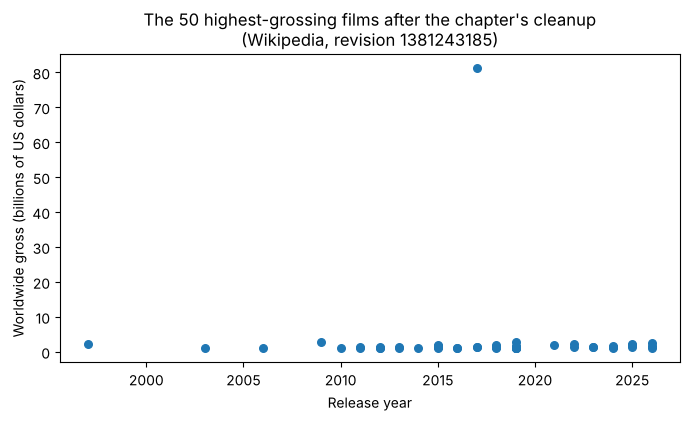

In [6]:
# Copy the chapter's cleanup: gross = "Worldwide gross" with every non-digit removed, as a number
#   (errors="coerce"); footnote_count = how many "[" are in "Ref". Print Title, gross, footnote_count for five rows
# Scatter-plot gross in billions of dollars against Year, with a title and labeled axes
films["gross"] = pd.to_numeric(
    films["Worldwide gross"].str.replace(r"[^0-9]", "", regex=True),
    errors="coerce"
)
films["footnote_count"] = films["Ref"].str.count(r"\[")
print(films[["Title", "gross", "footnote_count"]].head())

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(films["Year"], films["gross"] / 1e9, s=30)
ax.set_title("The 50 highest-grossing films after the chapter's cleanup\n(Wikipedia, revision 1381243185)")
ax.set_xlabel("Release year")
ax.set_ylabel("Worldwide gross (billions of US dollars)")
plt.show()

### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** find the point that doesn't belong. Sort `films` by `gross`, largest first, and look at the raw `Worldwide gross` cell beside the cleaned number.
**Share:** the film, what its cell says, what the cleanup turned it into, and why.

In [7]:
# Microsprint: sort films by gross, largest first, and print Title, "Worldwide gross", and gross for the top three
films.sort_values("gross", ascending=False)[["Title", "Worldwide gross", "gross"]].head(3)

,Title,Worldwide gross,gross
30,The Fate of the Furious,"F8$1,238,764,765",81238764765
0,Avengers: Endgame †,"$2,941,331,540",2941331540
1,Avatar,"$2,923,710,708",2923710708


<details>
<summary>💬 Discuss</summary>

- The chapter's regex keeps every digit. Why did that work for Titanic's `T$` and fail for this film?
- `errors="coerce"` turns what it can't read into NaN. Why couldn't it help here, and what kind of mistake can no setting catch?
- Would `films.head()` have shown you the problem? What does that say about how you check a column?

</details>

## Step 5 — Fix the cleanup, and count what changed (5 minutes)

The stray letters always come before the `$`, so take only what follows it. [`str.extract(r"\$([\d,]+)")`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.extract.html) returns the digits and commas after the dollar sign (the part in parentheses); remove the commas and convert. Then compare with Step 4: how many rows changed, and which film is the largest now?

In [8]:
# gross_fixed = the digits and commas after "$" (str.extract, column 0), commas removed, as a number
# Print the rows where gross and gross_fixed differ, and the film with the largest gross_fixed
films["gross_fixed"] = pd.to_numeric(
    films["Worldwide gross"].str.extract(r"\$([\d,]+)")[0].str.replace(",", ""),
    errors="coerce"
)
changed = films[films["gross"] != films["gross_fixed"]]
print(f"{len(changed)} row(s) changed")
print(changed[["Title", "Worldwide gross", "gross", "gross_fixed"]])

top = films.loc[films["gross_fixed"].idxmax()]
print(f"Largest now: {top['Title']}, ${top['gross_fixed']:,.0f}")

1 row(s) changed
                      Title   Worldwide gross        gross  gross_fixed
30  The Fate of the Furious  F8$1,238,764,765  81238764765   1238764765
Largest now: Avengers: Endgame †, $2,941,331,540


<details>
<summary>💬 Discuss</summary>

- The fix assumes every cell has a `$`. What would it do with one that doesn't, and how would you find out?
- The titles still carry `†` for films in theaters. If we joined this table to Step 2's by title, as Strategy 7 suggests, what would happen?
- The stray letters come from the article's own markup. Is fixing our code enough, or should someone fix the article too?

</details>

## Step 6 — An infobox, in two languages (11 minutes)

Strategies 4 and 5. A film's infobox is one record laid out as rows of a label (`<th>`) and a value (`<td>`). `read_html` would flatten it, so the chapter loops over its rows with BeautifulSoup and keeps a row only when it has both cells. Write that loop once, as `read_infobox(table)`, and use it twice. In English, the table has the class `infobox`. In French, the class you'd see in the Inspector, `infobox_v3`, sits on a `<div>` around the table, so the chapter anchors on the table's own `<caption>` with a CSS selector, [`select("table:has(caption)")`](https://www.crummy.com/software/BeautifulSoup/bs4/doc/#css-selectors-through-the-css-property). Pause a second between the two requests.

In [9]:
# Define read_infobox(table): the chapter's loop, keeping label -> value for rows with both a <th> and a <td>
# English: fetch The_Godfather, read the table with class "infobox", print how many facts and "Directed by"
# French: fetch Le_Parrain_(film); count the matches for "table.infobox_v3", then read
#   select("table:has(caption)")[0] and print how many facts and "Réalisation"
def read_infobox(table):
    facts = {}
    for row in table.find_all("tr"):
        label, value = row.find("th"), row.find("td")
        if label and value:
            facts[label.get_text(strip=True)] = value.get_text(" ", strip=True)
    return facts

response = requests.get("https://en.wikipedia.org/wiki/The_Godfather", headers=WIKI_HEADERS, timeout=30)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")
facts = read_infobox(soup.find("table", class_="infobox"))
print(len(facts), "facts. Directed by:", facts["Directed by"])
print(list(facts))

time.sleep(1)
response = requests.get("https://fr.wikipedia.org/wiki/Le_Parrain_(film)", headers=WIKI_HEADERS, timeout=30)
response.raise_for_status()
soup_fr = BeautifulSoup(response.text, "html.parser")
print(len(soup_fr.select("table.infobox_v3")), "tables with the class infobox_v3")
facts_fr = read_infobox(soup_fr.select("table:has(caption)")[0])
print(len(facts_fr), "facts. Réalisation:", facts_fr["Réalisation"])
print(list(facts_fr))

16 facts. Directed by: Francis Ford Coppola
['Directed by', 'Screenplay by', 'Based on', 'Produced by', 'Starring', 'Cinematography', 'Edited by', 'Music by', 'Productioncompanies', 'Distributed by', 'Release dates', 'Running time', 'Country', 'Language', 'Budget', 'Box office']


0 tables with the class infobox_v3
10 facts. Réalisation: Francis Ford Coppola
['Titre original', 'Réalisation', 'Scénario', 'Musique', 'Acteurs principaux', 'Sociétés de production', 'Pays de production', 'Genre', 'Durée', 'Sortie']


### ⏱ Microsprint (5 minutes, alone or in pairs)

A short version of Additional Exercise 3, with an infobox instead of a table.

**Do:** port `read_infobox()` to a third edition, Spanish Wikipedia's [El padrino (película)](https://es.wikipedia.org/wiki/El_padrino_(pel%C3%ADcula)). Try both of our selectors first, and see which one reaches the infobox.
**Share:** the selector that worked, how many facts it read, and the label Spanish uses for the director.

In [10]:
# Microsprint: fetch es.wikipedia.org/wiki/El_padrino_(película); count the matches for "table.infobox" and
#   "table:has(caption)", read the first match that is the infobox, and print how many facts and the director
response = requests.get("https://es.wikipedia.org/wiki/El_padrino_(película)", headers=WIKI_HEADERS, timeout=30)
response.raise_for_status()
soup_es = BeautifulSoup(response.text, "html.parser")
for selector in ["table.infobox", "table:has(caption)"]:
    print(f"{selector:20} {len(soup_es.select(selector))} matches")
facts_es = read_infobox(soup_es.select("table.infobox")[0])
print(len(facts_es), "facts. Dirección:", facts_es["Dirección"])

table.infobox        2 matches
table:has(caption)   1 matches
30 facts. Dirección: Francis Ford Coppola


<details>
<summary>💬 Discuss</summary>

- One English key reads `Productioncompanies`, with no space. Where did the space go? (Look at that label in the Inspector.)
- In week 5 the element picker labeled the CU Boulder article's infobox `table#mwCQ.infobox.vcard`: the class was on the table. On French Wikipedia, which element carries it, and why did that break `table.infobox_v3`?
- The three editions give different numbers of facts about the same film. Which one is the record of the film, if any?

</details>

## Step 7 — Cards that need to become rows: the Oscars (12 minutes)

Strategy 6. The page for the 98th Academy Awards has no `<table>`. Each award category is a *card* of nested `<div>`s, with one block per honoree inside it, winner first. oscars.org is built with Drupal, whose class names describe Drupal's fields (`field--name-field-award-categories`), not awards. This week's handout, *Cards to rows*, builds the loop one piece at a time, with DevTools figures; here we write it whole: the area, then its cards, then each card's name and honorees, then three fields per honoree, each guarded so that a missing field becomes `None` instead of an `AttributeError`. See the chapter's "Strategy 6: Cards That Need to Become Rows".

In [11]:
# Fetch the 2026 ceremony page with HEADERS; find the area div (class field--name-field-award-categories)
#   and the cards in it (paragraph--type--award-category); print how many cards
# For each card: its name (field--name-field-award-category-oscars), then one dict per honoree with category,
#   honoree_type, entity, and film, each None if missing. Make oscars26; print its shape and honoree_type counts
response = requests.get("https://www.oscars.org/oscars/ceremonies/2026", headers=HEADERS, timeout=30)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")

area = soup.find("div", class_="field--name-field-award-categories")
categories = area.find_all("div", class_="paragraph--type--award-category")
print(f"Found {len(categories)} categories")

results = []
for cat in categories:
    name_tag = cat.find(class_="field--name-field-award-category-oscars")
    if not name_tag:
        continue
    category_name = name_tag.get_text(strip=True)

    for h in cat.find_all("div", class_="paragraph--type--award-honoree"):
        type_tag = h.find(class_="field--name-field-honoree-type")
        entity_tag = h.find(class_="field--name-field-award-entities")
        film_tag = h.find(class_="field--name-field-award-film")

        results.append({
            "category": category_name,
            "honoree_type": type_tag.get_text(strip=True) if type_tag else None,
            "entity": entity_tag.get_text(strip=True) if entity_tag else None,
            "film": film_tag.get_text(strip=True) if film_tag else None,
        })

oscars26 = pd.DataFrame(results)
print(oscars26.shape)
print(oscars26["honoree_type"].value_counts())
oscars26.head()

Found 24 categories
(125, 4)
honoree_type
Nominees    100
Winner       25
Name: count, dtype: int64


,category,honoree_type,entity,film
0,Actor in a Leading Role,Winner,Michael B. Jordan,Sinners
1,Actor in a Leading Role,Nominees,Timothée Chalamet,Marty Supreme
2,Actor in a Leading Role,Nominees,Leonardo DiCaprio,One Battle after Another
3,Actor in a Leading Role,Nominees,Ethan Hawke,Blue Moon
4,Actor in a Leading Role,Nominees,Wagner Moura,The Secret Agent


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** which film had the most nominations? Count the rows per film with `value_counts()`. Then check the leader: count the rows whose `film` is that film *or* whose `entity` mentions it.
**Share:** the film, and its count both ways.

In [12]:
# Microsprint: print the five films with the most rows; then count the rows whose film is the top film
#   or whose entity contains its title (str.contains with regex=False, na=False)
counts = oscars26["film"].value_counts()
print(counts.head())
top_film = counts.index[0]
mentions = (oscars26["film"] == top_film) | oscars26["entity"].str.contains(top_film, regex=False, na=False)
print(f"{top_film}: {counts.iloc[0]} rows by film, {mentions.sum()} rows that mention it")

film
Sinners                     15
One Battle after Another    13
Marty Supreme                9
Frankenstein                 9
Sentimental Value            8
Name: count, dtype: int64
Sinners: 15 rows by film, 16 rows that mention it


<details>
<summary>💬 Discuss</summary>

- 25 winners for 24 categories: a bug in our loop, or a fact about the night? How did the handout settle it?
- The column we named `film` holds a country for International Feature Film and a song's title for Original Song. Who decides what a column means, we or the site?
- Week 4's House XML named its contents in its tags, such as `<party>`. How good a guide are Drupal's class names, by comparison?

</details>

## Step 8 — One function, several ceremonies (8 minutes)

Once the parser works for one year, wrap it in a function. The chapter's `parse_oscar_ceremony(year)` fetches through `responsible_get()` from week 2, which names you, pauses after every request, and returns `None` instead of crashing when a request fails. Paste `responsible_get()` from chapter 2 (or your week 2 notebook), as chapter 6 does, then define `parse_oscar_ceremony()` around Step 7's loop and collect three ceremonies. See the chapter's "Abstracting into Functions".

In [13]:
# Paste responsible_get() from chapter 2 (week 2), as chapter 6 does
# Define parse_oscar_ceremony(year): responsible_get the year's page, then Step 7's loop, adding a "year" key;
#   return an empty DataFrame if the request fails or the area div is missing
# Collect 2024, 2025, and 2026 into one DataFrame, oscars; print its categories and honorees per year
import logging

def responsible_get(url, headers=None, delay=1.0):
    """Make an HTTP GET request with responsible defaults.

    Parameters
    ----------
    url : str
        The URL to request
    headers : dict, optional
        Custom headers; a default User-Agent is added if none provided
    delay : float
        Seconds to wait after the request (default: 1.0)

    Returns
    -------
    requests.Response or None
        The response object, or None if the request failed
    """
    default_headers = {
        "User-Agent": "WebDataScience/1.0 (student-project; your-email@colorado.edu)"
    }
    if headers:
        default_headers.update(headers)

    try:
        response = requests.get(url, headers=default_headers, timeout=30)
        response.raise_for_status()  # Treat 4xx/5xx statuses as failures
        logging.info(f"{response.status_code} {url}")
        time.sleep(delay)
        return response
    except requests.exceptions.HTTPError as e:
        logging.error(f"HTTP error: {e}")
        time.sleep(delay)  # A failed request still counts against the server
        return None
    except requests.exceptions.RequestException as e:
        logging.error(f"Request failed ({type(e).__name__}): {url}")
        return None


def parse_oscar_ceremony(year):
    """Fetch and parse one Oscars ceremony page into one row per honoree.

    Parameters
    ----------
    year : int
        The ceremony year to fetch and parse

    Returns
    -------
    pd.DataFrame
        DataFrame with columns: category, honoree_type, entity, film, year
    """
    url = f"https://www.oscars.org/oscars/ceremonies/{year}"
    response = responsible_get(url)
    if response is None:
        print(f"Request failed for {year}")
        return pd.DataFrame()

    soup = BeautifulSoup(response.text, "html.parser")

    area = soup.find("div", class_="field--name-field-award-categories")
    if not area:
        print(f"No categories found for {year} — page structure may differ")
        return pd.DataFrame()

    rows = []
    for cat in area.find_all("div", class_="paragraph--type--award-category"):
        name_tag = cat.find(class_="field--name-field-award-category-oscars")
        if not name_tag:
            continue
        category_name = name_tag.get_text(strip=True)

        for h in cat.find_all("div", class_="paragraph--type--award-honoree"):
            type_tag = h.find(class_="field--name-field-honoree-type")
            entity_tag = h.find(class_="field--name-field-award-entities")
            film_tag = h.find(class_="field--name-field-award-film")

            rows.append({
                "category": category_name,
                "honoree_type": type_tag.get_text(strip=True) if type_tag else None,
                "entity": entity_tag.get_text(strip=True) if entity_tag else None,
                "film": film_tag.get_text(strip=True) if film_tag else None,
                "year": year,
            })

    return pd.DataFrame(rows)


all_years = [parse_oscar_ceremony(year) for year in range(2024, 2027)]
oscars = pd.concat(all_years, ignore_index=True)
print(f"Collected {len(oscars)} honorees across {oscars['year'].nunique()} ceremonies")
oscars.groupby("year").agg(categories=("category", "nunique"), honorees=("category", "size"))

Collected 365 honorees across 3 ceremonies


,categories,honorees
year,,
2024,23,120
2025,23,120
2026,24,125


### ⏱ Microsprint (5 minutes, alone or in pairs)

A short version of Additional Exercise 2.

**Do:** run `parse_oscar_ceremony()` for a ceremony from before you were born (the key uses 1990). Count its categories and honorees, and look for rows with no film.
**Share:** the year, its two counts, and the category of any row whose `film` is `None`.

In [14]:
# Microsprint: parse one more ceremony (the key uses 1990); print how many categories and honorees it has,
#   and the category and honoree_type of every row whose film is None
old = parse_oscar_ceremony(1990)
print(f"{old['category'].nunique()} categories, {len(old)} honorees")
old[old["film"].isna()][["category", "honoree_type"]]

24 categories, 104 honorees


,category,honoree_type
58,Jean Hersholt Humanitarian Award,Winner


<details>
<summary>💬 Discuss</summary>

- In 2026 the `else None` guards never fired. Which row made one fire in your year, and what would the loop have done without it?
- If you parsed every ceremony since 1929, what would you check before comparing the number of categories or nominees across years?
- Week 2's `responsible_get()` sleeps even after a failed request. Why does a failure still count against the server?

</details>

## Step 9 — Where the patterns stop: custom tags, and a page built by JavaScript (7 minutes)

Two last shapes. **Strategy 7:** Rotten Tomatoes' [Movies in Theaters](https://www.rottentomatoes.com/browse/movies_in_theaters/) grid is cards too, but its tags are the site's own, `<media-info-tile>` and `<rt-text>`, told apart by their `slot` and `data-qa` attributes. BeautifulSoup navigates them like any tag; what's new is that a second site needs a second parser. **Strategy 8:** some pages arrive nearly empty and are filled in by JavaScript in the browser, and `requests` never runs JavaScript. The chapter's example is IMDb, which Step 1 told us to leave alone, so we use [quotes.toscrape.com](https://quotes.toscrape.com/), a site built for scraping practice: it serves the same quotes at `/`, as HTML, and at `/js/`, drawn by a script. Count the `div.quote`s each one gives `requests`.

In [15]:
# Rotten Tomatoes: fetch the in-theaters page; count its <media-info-tile> tags, and the tiles whose
#   rt-text with slot="criticsScore" is missing or empty
# Then fetch https://quotes.toscrape.com/ and https://quotes.toscrape.com/js/, a second apart, and print
#   each one's status, length, number of div.quote, and number of <script> tags
response = requests.get("https://www.rottentomatoes.com/browse/movies_in_theaters/", headers=HEADERS, timeout=30)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")
tiles = soup.find_all("media-info-tile")
scores = []
for tile in tiles:
    score = tile.find("rt-text", attrs={"slot": "criticsScore"})
    scores.append(score.get_text(strip=True) if score else "")
print(f"{len(tiles)} tiles, {scores.count('')} with no Tomatometer yet")

for url in ["https://quotes.toscrape.com/", "https://quotes.toscrape.com/js/"]:
    time.sleep(1)
    response = requests.get(url, headers=HEADERS, timeout=30)
    page = BeautifulSoup(response.text, "html.parser")
    print(f"{url:34} {response.status_code} {len(response.text):6,} characters, "
          f"{len(page.find_all('div', class_='quote'))} quotes, {len(page.find_all('script'))} scripts")

28 tiles, 16 with no Tomatometer yet


https://quotes.toscrape.com/       200 11,021 characters, 10 quotes, 0 scripts


https://quotes.toscrape.com/js/    200  5,806 characters, 0 quotes, 2 scripts


<details>
<summary>💬 Discuss</summary>

- The `/js/` page answered 200 with a body, and no quotes in it. Week 5 said the Inspector shows the DOM, not what the server sent. Where are the quotes in what `requests` got? (Try View Source.)
- Place today's sites on the chapter's 2×2 of single or multiple sites and consistent or inconsistent design. Which quadrant needs the most code?
- To ask whether a film's box office tracks its Tomatometer, you'd join The Numbers to Rotten Tomatoes by title. What have we seen today that would break that join?

</details>

## Step 10 — What did we learn? (4 minutes)

In a few sentences, as comments or in a Markdown cell:

- Which of the chapter's sites did `robots.txt` let us fetch, and what did we do for the others?
- How many films did The Numbers' desktop table give us, and what would the chapter's `tables[1]` have given under each parser?
- What did the chapter's cleanup do to one film's gross, and what caught it?
- How many honorees did we collect across 2024–2026, and what did an older ceremony show about the guards?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday). Choose a table other than the lab's list of highest-grossing films.

- Step 1, choose and check: Step 1's `RobotFileParser` loop (week 2), and Step 3's fetch with `WIKI_HEADERS`.
- Step 2, cache the raw HTML: Step 3 fetched once and parsed the text it kept; save that text to a file instead (Additional Exercise 4 is the longer version).
- Step 3, extract with `read_html()`: Step 3's `read_html(StringIO(...))`, the table count, and the index.
- Step 4, clean it: Steps 4–5's regex cleanup, `pd.to_numeric(errors="coerce")`, and the check that found what they missed.
- Step 5, visualize: Step 4's titled, labeled plot (yours is a bar chart).
- Step 6, look under the hood: Step 2's `find_all("table")`, each table's `class`, and the header row read with `find_all(["td", "th"])`.
- Step 7, interpret: Steps 2 and 6, where a table index and a class name broke.

In [16]:
# Your answers here, as comments
# Four of six: The Numbers, Wikipedia, oscars.org, and Rotten Tomatoes allow the chapter's pages; Box Office Mojo
#   and IMDb disallow every path to unnamed crawlers, so we skipped them (Step 9 used quotes.toscrape.com/js/).
# The desktop table gave 81 films, and the guard's skipped "Reporting movies: 81" row agrees. tables[1] is the
#   phone table: html.parser nests its unclosed rows (405 cells in the first data row), so the loop keeps 1 film;
#   lxml closes them and gives 5 cells per row.
# The regex kept the 8 in The Fate of the Furious's "F8$1,238,764,765": 81,238,764,765 dollars, 81 billion.
#   The plot showed one point near 80 billion; the sort named it. Extracting after "$" changed only that row.
# 365 honorees in 2024-2026 (120, 120, and 125; 23, 23, and 24 categories). In 1990 (24 categories, 104 honorees),
#   the Jean Hersholt Humanitarian Award's winner has no film field: the guard recorded None where an unguarded
#   .get_text() would have stopped the loop with an AttributeError.

## Friday: from the lab to the textbook (15 minutes)

What did the lab turn up that the chapter should know? Some places to start:

- **Step 1:** the chapter's Strategies 1 and 8 request pages whose `robots.txt` disallows every unnamed crawler. What should the chapter use, or say, instead?
- **Step 2:** the chapter takes `tables[1]` and prints a header with an empty column and a `Movie` column. Compare both with what you got.
- **Steps 4–5:** the chapter's regex and The Fate of the Furious. Is a fix, a warning, or a check the better revision?
- **Step 6:** the `Productioncompanies` key, or a third language edition as an example of porting.
- **A microsprint** that would make a good exercise, such as the 1990 ceremony's missing film.

[`handouts/common/revision-framework.md`](../../handouts/common/revision-framework.md) says how to propose a revision.